# MD-Agreement: Data Preparation and Annotator Disagreement

**Dataset:** MD-Agreement (LeWiDi 2023)  
**Task:** Binary offensiveness classification

This notebook checks the original annotations, examines label ambiguity in the training data, and exports consistent train/dev/test files for the hard-label and soft-label experiments. The official splits are preserved.

## 1. Loading and preparing the data

In [73]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

DATA_DIR = Path("../data/raw")
OUTPUT_DIR = Path("../data/processed")

In [74]:
def load_split(split):
    with (DATA_DIR / f"MD-Agreement_{split}.json").open(encoding="utf-8") as f:
        records = json.load(f)
    df = pd.DataFrame.from_dict(records, orient="index")
    df.index.name = "record_id"
    return df.reset_index()


def prepare_dataset(df):
    df = df.copy()
    df["hard_label"] = df["hard_label"].astype(int)
    df["soft_label_0"] = df["soft_label"].map(lambda x: float(x["0"]))
    df["soft_label_1"] = df["soft_label"].map(lambda x: float(x["1"]))

    p = df[["soft_label_0", "soft_label_1"]].to_numpy()
    # Zero-probability classes contribute zero to Shannon entropy.
    df["annotation_entropy"] = -(p * np.log2(np.where(p > 0, p, 1))).sum(axis=1)
    df["entropy_level"] = df["annotation_entropy"].round(3)
    df["domain"] = df["other_info"].map(lambda x: x["domain"])
    return df


splits = {
    split: prepare_dataset(load_split(split))
    for split in ("train", "dev", "test")
}
train_df = splits["train"]

pd.DataFrame({
    "split": list(splits),
    "examples": [len(df) for df in splits.values()],
})

,split,examples
0,train,6592
1,dev,1104
2,test,3057


## 2. Data quality and label consistency

In [75]:
quality = []
for split, df in splits.items():
    votes = df["annotations"].map(lambda s: [int(x) for x in s.split(",")])
    counts_match = (votes.map(len) == df["number of annotations"]).all()
    hard_match = (votes.map(lambda v: int(sum(v) > len(v) / 2)) == df["hard_label"]).all()
    soft_match = np.allclose(
        votes.map(lambda v: sum(v) / len(v)).to_numpy(),
        df["soft_label_1"].to_numpy(),
    )

    quality.append({
        "split": split,
        "missing_values": int(df.isna().sum().sum()),
        "empty_texts": int(df["text"].str.strip().eq("").sum()),
        "duplicate_texts": int(df["text"].duplicated().sum()),
        "annotation_counts_valid": bool(counts_match),
        "hard_labels_valid": bool(hard_match),
        "soft_labels_valid": bool(soft_match),
        "soft_probabilities_valid": bool(np.allclose(df["soft_label_0"] + df["soft_label_1"], 1)),
    })

quality_df = pd.DataFrame(quality).set_index("split")
quality_df

,missing_values,empty_texts,duplicate_texts,annotation_counts_valid,hard_labels_valid,soft_labels_valid,soft_probabilities_valid
split,,,,,,,
train,0,0,0,True,True,True,True
dev,0,0,0,True,True,True,True
test,0,0,0,True,True,True,True


In [76]:
text_sets = {split: set(df["text"]) for split, df in splits.items()}
overlap = {
    "train / dev": len(text_sets["train"] & text_sets["dev"]),
    "train / test": len(text_sets["train"] & text_sets["test"]),
    "dev / test": len(text_sets["dev"] & text_sets["test"]),
}
print("Overlapping texts:", overlap)
assert all(count == 0 for count in overlap.values())
assert quality_df["missing_values"].eq(0).all()
assert quality_df["empty_texts"].eq(0).all()
assert quality_df["duplicate_texts"].eq(0).all()
assert quality_df["annotation_counts_valid"].all()
assert quality_df["hard_labels_valid"].all()
assert quality_df["soft_labels_valid"].all()
assert quality_df["soft_probabilities_valid"].all()

Overlapping texts: {'train / dev': 0, 'train / test': 0, 'dev / test': 0}


## 3. Exploratory analysis

The analyses below use the **training split only**.

### 3.1 Class and annotation distributions

In [77]:
label_counts = train_df["hard_label"].value_counts().sort_index()
label_summary = pd.DataFrame({
    "count": label_counts,
    "share_pct": (100 * label_counts / len(train_df)).round(1),
})
label_summary.index.name = "hard_label"
label_summary

,count,share_pct
hard_label,,
0,4630,70.2
1,1962,29.8


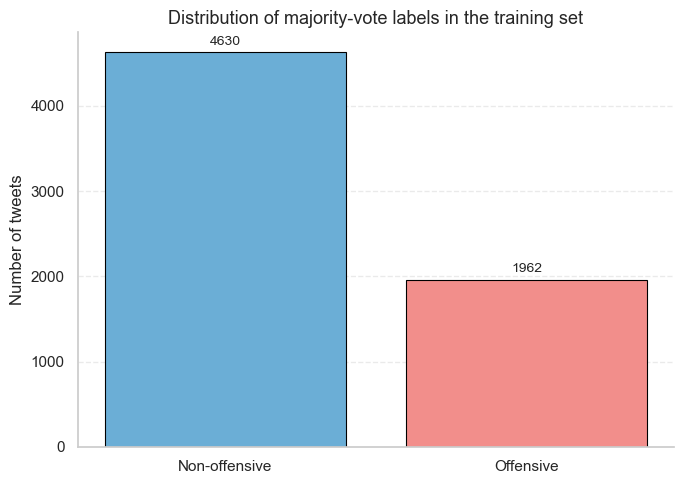

In [78]:
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["Non-offensive", "Offensive"],
    label_counts.values,
    color=["#6BAED6", "#F28E8B"],
    edgecolor="black",
    linewidth=0.8
)

ax.set_title("Distribution of majority-vote labels in the training set", fontsize=13)
ax.set_xlabel("")
ax.set_ylabel("Number of tweets")

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 50,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

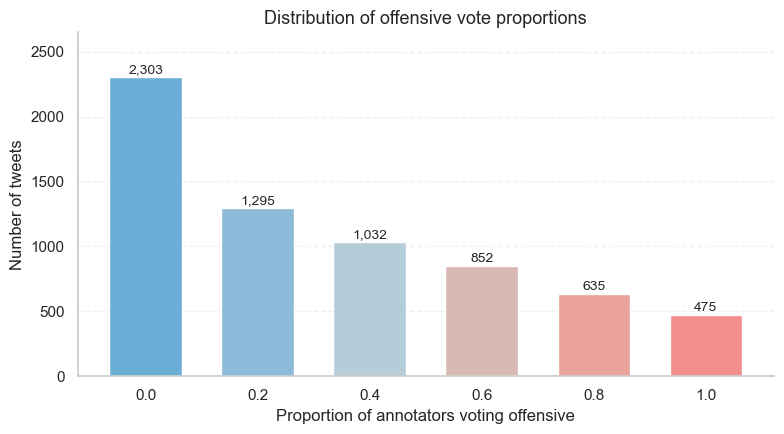

In [79]:
soft_counts = train_df["soft_label_1"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4.5))

colors = [
    "#6BAED6", "#8CBBD9", "#B5CCD9",
    "#D9B9B4", "#E9A29C", "#F28E8B"
]

bars = ax.bar(
    soft_counts.index.astype(str),
    soft_counts.values,
    color=colors,
    width=0.65
)

ax.set_title("Distribution of offensive vote proportions", fontsize=13)
ax.set_xlabel("Proportion of annotators voting offensive")
ax.set_ylabel("Number of tweets")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 30,
        f"{int(height):,}",
        ha="center",
        fontsize=10
    )

ax.set_ylim(0, soft_counts.max() * 1.15)

plt.tight_layout()
plt.show()


### 3.2 Disagreement levels and majority-vote labels

Annotation entropy is used to quantify disagreement among annotators. It is calculated from the empirical label distribution using Shannon entropy:

$$
H = -\sum_{c \in \{0,1\}} p_c \log_2 p_c
$$

With five binary annotations per tweet, there are three possible entropy levels: 0 (5:0), 0.722 (4:1), and 0.971 (3:2). Higher values indicate stronger disagreement.


In [80]:
entropy_counts = train_df["entropy_level"].value_counts().sort_index()
entropy_summary = pd.DataFrame({
    "count": entropy_counts,
    "share_pct": (100 * entropy_counts / len(train_df)).round(2),
})
entropy_summary.index.name = "entropy_bits"
entropy_summary

,count,share_pct
entropy_bits,,
-0.000,2778,42.14
0.722,1930,29.28
0.971,1884,28.58


In [81]:
entropy_by_label = pd.crosstab(
    train_df["entropy_level"], train_df["hard_label"], normalize="columns"
) * 100
entropy_by_label.round(2)

hard_label,0,1
entropy_level,,
-0.000,49.74,24.21
0.722,27.97,32.36
0.971,22.29,43.43


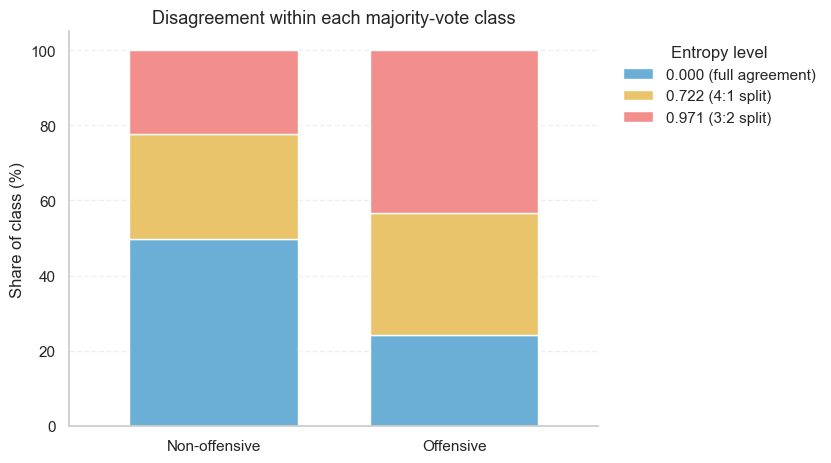

In [82]:
ax = entropy_by_label.T.plot(
    kind="bar",
    stacked=True,
    figsize=(8.5, 4.8),
    color=["#6BAED6", "#E9C46A", "#F28E8B"],
    edgecolor="white",
    width=0.7
)

ax.set_title("Disagreement within each majority-vote class", fontsize=13)
ax.set_xlabel("")
ax.set_ylabel("Share of class (%)")

ax.set_xticklabels(["Non-offensive", "Offensive"], rotation=0)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    ["0.000 (full agreement)", "0.722 (4:1 split)", "0.971 (3:2 split)"],
    title="Entropy level",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
plt.show()



Highly ambiguous examples are more frequent among majority-offensive tweets (43.4%) than majority-non-offensive tweets (22.3%). Removing high-entropy examples may therefore alter the class distribution of the training set.


### 3.3 Differences across domains

In [83]:
domain_stats = train_df.groupby("domain")["annotation_entropy"].agg(
    n="size", mean_entropy="mean", median_entropy="median"
)
domain_stats.round(3)

,n,mean_entropy,median_entropy
domain,,,
BLM,2351,0.386,-0.000
Covid-19,2206,0.558,0.722
Elections2020,2035,0.533,0.722


In [84]:
domain_entropy_pct = pd.crosstab(
    train_df["domain"], train_df["entropy_level"], normalize="index"
) * 100
domain_entropy_pct.round(2)

entropy_level,-0.000,0.722,0.971
domain,,,
BLM,53.59,25.90,20.50
Covid-19,34.36,31.82,33.82
Elections2020,37.35,30.42,32.24


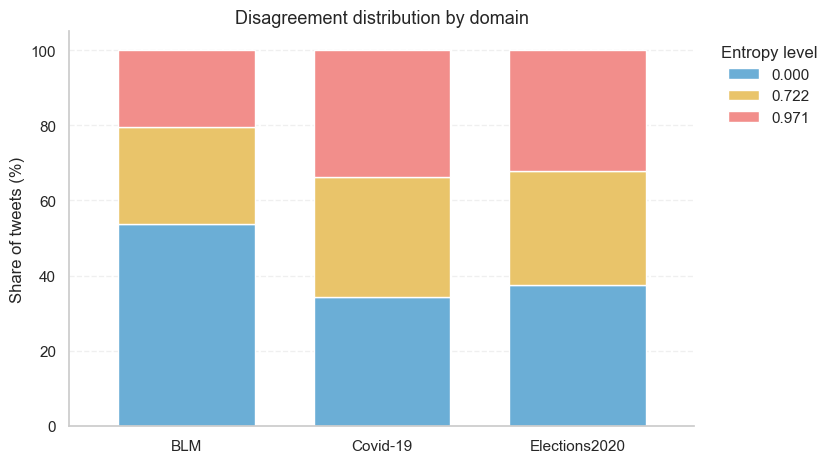

In [85]:
ax = domain_entropy_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(8.5, 4.8),
    color=["#6BAED6", "#E9C46A", "#F28E8B"],
    edgecolor="white",
    width=0.7
)

ax.set_title("Disagreement distribution by domain", fontsize=13)
ax.set_xlabel("")
ax.set_ylabel("Share of tweets (%)")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    title="Entropy level",
    labels=["0.000", "0.722", "0.971"],
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


The proportion of highly ambiguous examples varies across domains, from 20.5% in BLM to 33.8% in Covid-19. Entropy-based filtering may therefore change the domain composition of the training data.

## 4. Observations and implications

The training data are imbalanced: **70.2%** of tweets have majority-vote label 0, compared with **29.8%** for label 1. Disagreement is common: **57.9%** of tweets have at least one dissenting annotation, while **28.6%** have the most ambiguous vote split (3:2).

Ambiguity differs by class and domain. The highest disagreement level occurs in **43.4%** of majority-offensive tweets, compared with **22.3%** of majority-non-offensive tweets. Across domains, the corresponding shares range from **20.5%** (BLM) to **33.8%** (Covid-19). Filtering by entropy may therefore change the class and domain composition of the training set, not just its size. These shifts should be checked in the later training experiments; they do not by themselves demonstrate any advantage of soft-label training.

## 5. Export for downstream experiments

The outputs retain the original record ID, text, both label formats, entropy, domain and split. No ambiguity filtering is applied here; the training experiments will create filtered variants while keeping dev and test unchanged.

In [86]:
export_columns = [
    "record_id", "text", "hard_label", "soft_label_0", "soft_label_1",
    "annotation_entropy", "domain", "split",
]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for split, df in splits.items():
    out_path = OUTPUT_DIR / f"{split}.csv"
    df[export_columns].to_csv(out_path, index=False)
    restored = pd.read_csv(out_path)
    assert restored.shape == (len(df), len(export_columns))
    assert restored.isna().sum().sum() == 0
    assert np.allclose(restored["soft_label_0"] + restored["soft_label_1"], 1)
    print(f"{out_path}: {restored.shape[0]} rows")

../data/processed/train.csv: 6592 rows
../data/processed/dev.csv: 1104 rows
../data/processed/test.csv: 3057 rows
